In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   
import numpy as np
import statistics as stats
import scipy.stats as st
from sklearn.preprocessing import LabelEncoder
import scipy.stats as stats
from statsmodels.stats.power import TTestIndPower, TTestPower, GofChisquarePower



In [65]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


1. longitude: A measure of how far west a house is; a higher value is farther west

2. latitude: A measure of how far north a house is; a higher value is farther north

3. housingMedianAge: Median age of a house within a block; a lower number is a newer building

4. totalRooms: Total number of rooms within a block

5. totalBedrooms: Total number of bedrooms within a block

6. population: Total number of people residing within a block

7. households: Total number of households, a group of people residing within a home unit, for a block

8. medianIncome: Median income for households within a block of houses (measured in tens of thousands of US Dollars)

9. medianHouseValue: Median house value for households within a block (measured in US Dollars)

10. oceanProximity: Location of the house w.r.t ocean/sea

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [67]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [68]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [69]:
# Im gonna drop the null values for simplicity because they are only 1% of the data
df.dropna(inplace=True)

In [70]:
df.shape

(20433, 10)

<Axes: xlabel='ocean_proximity'>

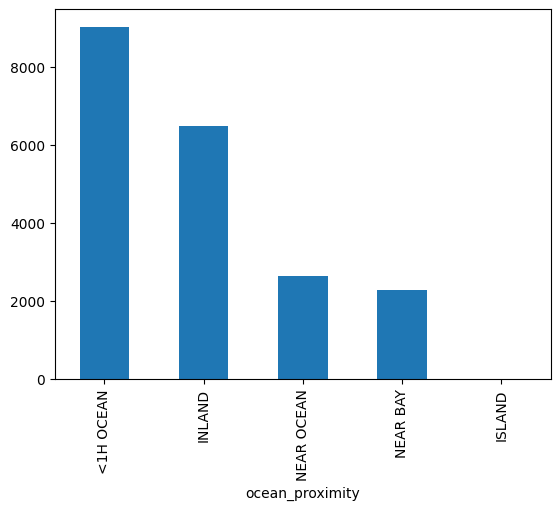

In [71]:
df.ocean_proximity.value_counts().plot(kind='bar')

In [72]:
label_encoder = LabelEncoder()
df['ocean_proximity'] = label_encoder.fit_transform(df['ocean_proximity'])

<Axes: xlabel='ocean_proximity'>

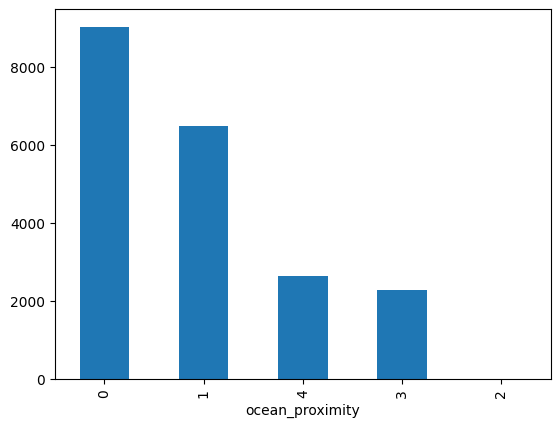

In [73]:
df.ocean_proximity.value_counts().plot(kind='bar')

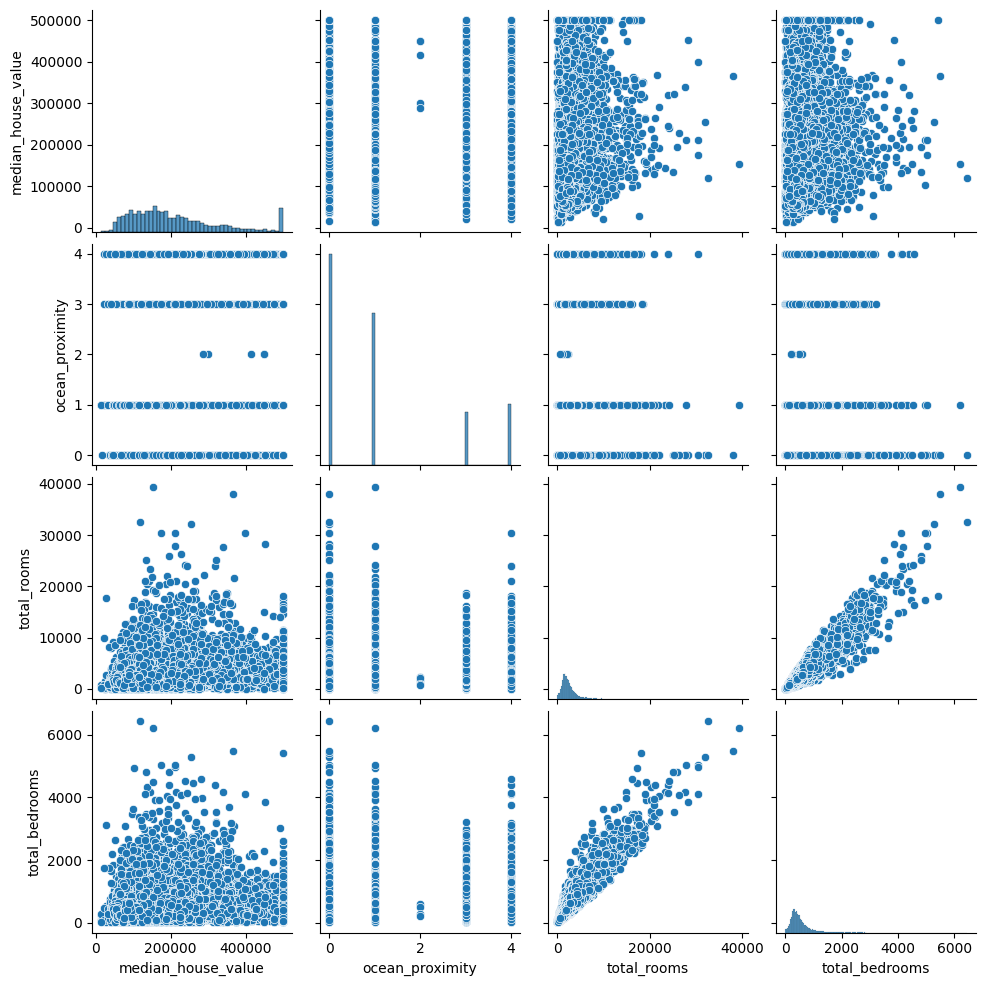

In [74]:
sns.pairplot(df[['median_house_value' , 'ocean_proximity' , 'total_rooms' , 'total_bedrooms']])

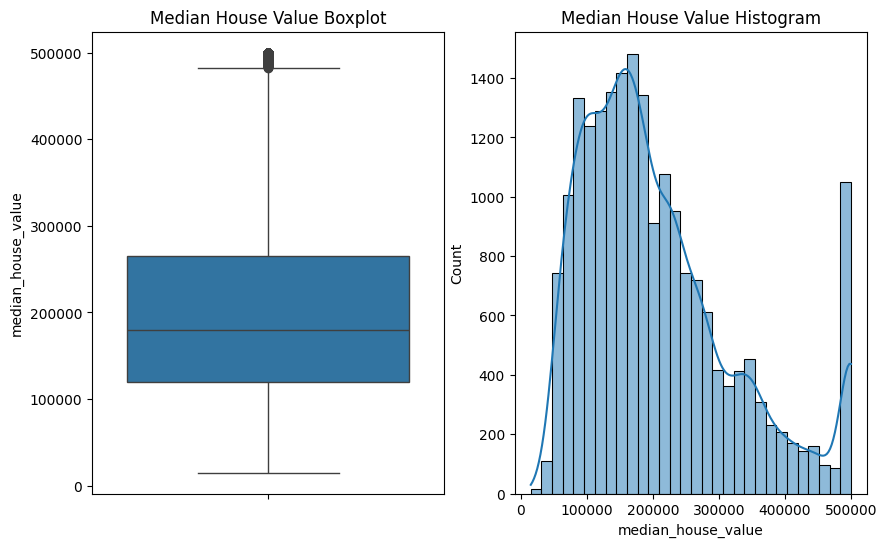

In [75]:
plt.subplots(1,2,figsize=(10,6))
plt.subplot(1,2,1)
plt.title("Median House Value Boxplot")
sns.boxplot(df.median_house_value)  
plt.subplot(1,2,2)
plt.title("Median House Value Histogram")
sns.histplot(df.median_house_value , bins=30, kde=True)
plt.show()

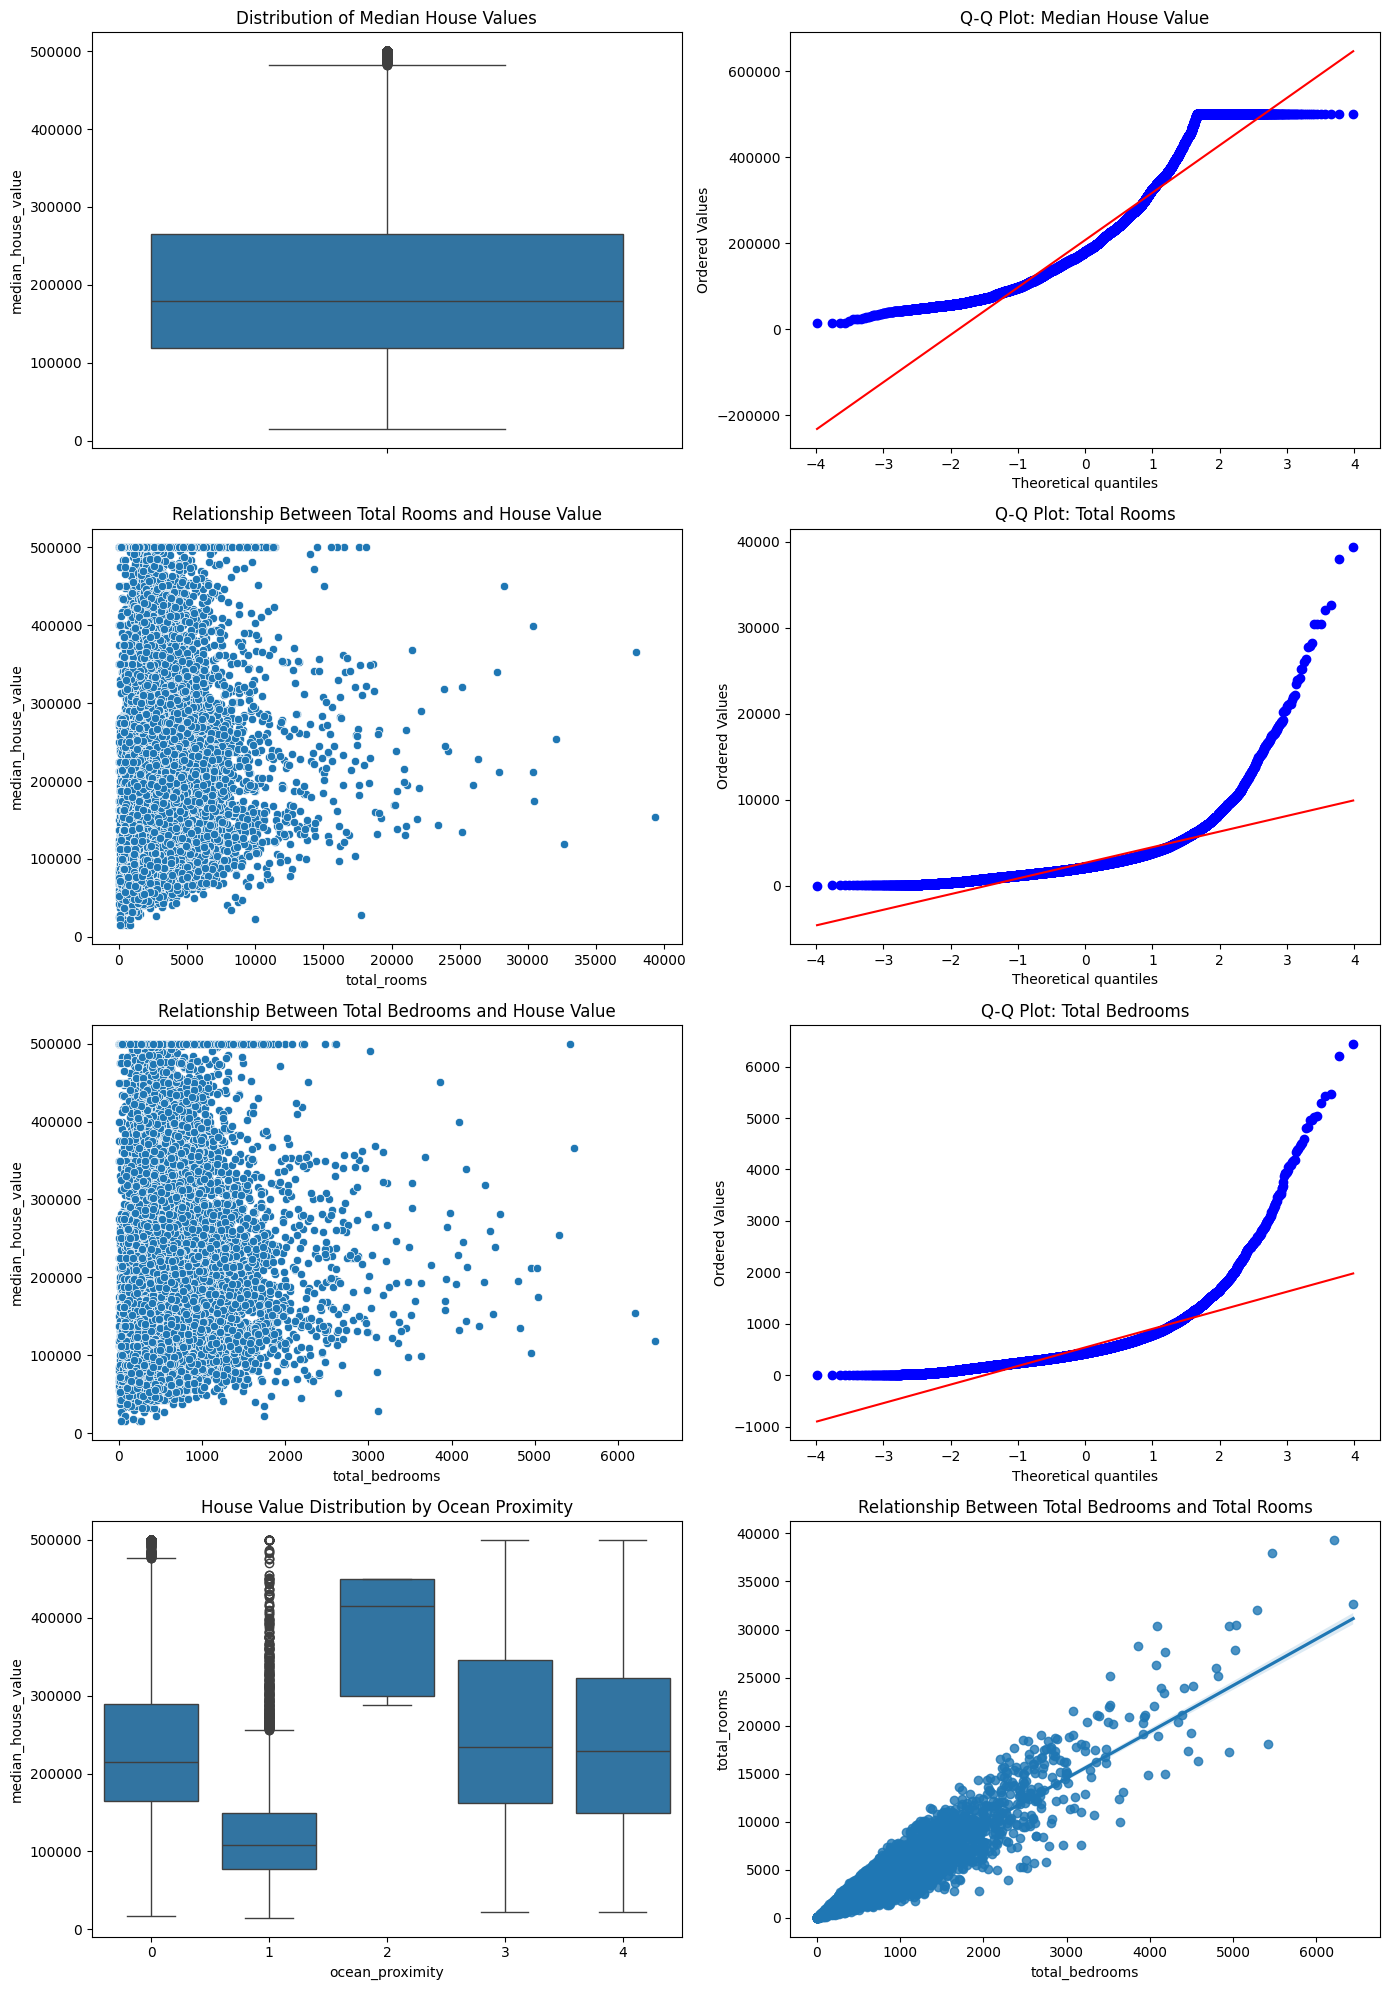

In [76]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))

# Median House Value
sns.boxplot(y=df['median_house_value'], ax=axes[0,0])
axes[0,0].set_title("Distribution of Median House Values")

stats.probplot(df['median_house_value'].dropna(), dist="norm", plot=axes[0,1])
axes[0,1].set_title("Q-Q Plot: Median House Value")

# Total Rooms vs House Value
sns.scatterplot(x=df['total_rooms'], y=df['median_house_value'], ax=axes[1,0])
axes[1,0].set_title("Relationship Between Total Rooms and House Value")

stats.probplot(df['total_rooms'].dropna(), dist="norm", plot=axes[1,1])
axes[1,1].set_title("Q-Q Plot: Total Rooms")

# Total Bedrooms vs House Value
sns.scatterplot(x=df['total_bedrooms'], y=df['median_house_value'], ax=axes[2,0])
axes[2,0].set_title("Relationship Between Total Bedrooms and House Value")

stats.probplot(df['total_bedrooms'].dropna(), dist="norm", plot=axes[2,1])
axes[2,1].set_title("Q-Q Plot: Total Bedrooms")

# Ocean Proximity vs House Value (categorical fix)
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df, ax=axes[3,0])
axes[3,0].set_title("House Value Distribution by Ocean Proximity")


sns.regplot(x=df['total_bedrooms'], y=df['total_rooms'], ax=axes[3,1])
axes[3,1].set_title("Relationship Between Total Bedrooms and Total Rooms")

plt.tight_layout()
plt.show()

In [77]:
stat, p = stats.shapiro(df['median_house_value'].dropna())
print(f'Shapiro: Statistics={stat:.3f}, p-value={p:.3f}')

# An alternative for large N
stat, p = stats.normaltest(df['median_house_value'].dropna())
print(f"DAgostino K^2: Statistics={stat:.3f}, p-value={p:.3f}")


group1 = df[df['ocean_proximity'] == 1]['median_house_value']
group2 = df[df['ocean_proximity'] == 3]['median_house_value']
stat, p = stats.levene(group1, group2)
print(f'Levene: Statistics={stat:.3f}, p-value={p:.3f}')

Shapiro: Statistics=0.912, p-value=0.000
DAgostino K^2: Statistics=2408.542, p-value=0.000
Levene: Statistics=1306.526, p-value=0.000


/home/manheim666/.local/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 20433.
  res = hypotest_fun_out(*samples, **kwds)


After checking all the assumptions, it becomes quite clear that the dataset does not behave in a nice statistical way. Both the Shapiro and DAgostino tests returned p-values equal to 0.000, which is way below 0.05 threshold. This basically means that the distribution of median_house_value is not normal . There was a warning saying that Shapiro might not be accurate for such a large sample (N > 5000), but the DAgostino test also confirms the same result, so we can be confident that it's not normally distributed.

The Levene’s test also gave a p-value of 0.000, which shows that the variances between groups (different ocean proximity categories) are not equal. So we are also violating the equal variance assumption, which is important for tests like the independent t-test or ANOVA. The spread of house prices is very different depending on location, which makes sense in real life too.

Because of these two main issues (non-normal distribution and unequal variances) it would not be correct to use standard parametric tests. Even though the dataset is quite large (around 20k rows), which sometimes helps with normality due to central limit theorem, the presence of strong skewness and the artificial $500k cap makes the distribution clearly non-normal. So we can’t really rely on mean-based methods here

For this reason, I decided to use non-parametric tests. For example, instead of an independent t-test, I will use the Mann-Whitney U test, because it compares medians/ranks and is much more robust to skewed data and outliers. Similarly, for correlation, I will use Spearman’s rank correlation instead of Pearson, since the relationship between variables like total rooms and house value is not perfectly linear and contains extreme values.

<pre>






</pre>

### Case A

H0 - There is no difference in the distribution of house values between Inland and Near Ocean properties.

H1 - Near Ocean properties have a significantly different distribution of house values than Inland properties.

<pre>Test - Mann-WhitneyU
Mann-Whitney is used for independent data when teh data is not normally distributed and has some outliers, it's basically a non parametric distribution that doesnt focus on mean but ranks and the lengths</pre>

In [78]:
inland = df[df['ocean_proximity'] == 1]
near_ocean = df[df['ocean_proximity'] == 4]


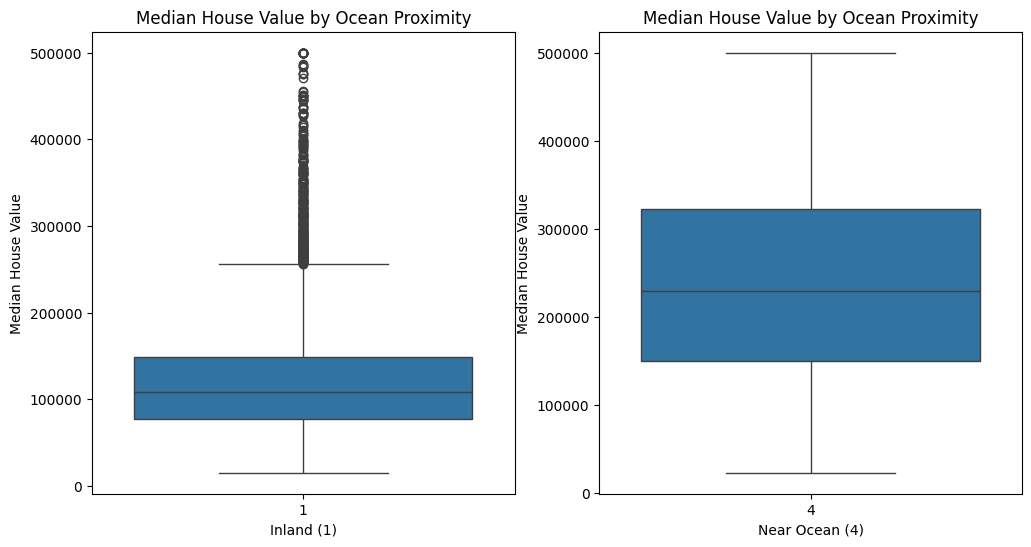

In [79]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x='ocean_proximity', y='median_house_value', data=inland)
plt.xlabel("Inland (1)")
plt.ylabel("Median House Value")
plt.title("Median House Value by Ocean Proximity")
plt.subplot(1, 2, 2)
sns.boxplot(x='ocean_proximity', y='median_house_value', data=near_ocean)
plt.xlabel("Near Ocean (4)")
plt.ylabel("Median House Value")

plt.title("Median House Value by Ocean Proximity")
plt.show()

In [80]:
u_statistic, p_value = stats.mannwhitneyu(inland['median_house_value'], near_ocean['median_house_value'], alternative='two-sided')
print(f"U-statistic: {u_statistic}\nP-value: {p_value}")

U-statistic: 2910397.5
P-value: 0.0


We reject the null hypothesis(H0) as p(which is 0.0) is much smaller than 0.05, this means theres a significantly different between distributions of Inland and Near Ocean houses. 

In [81]:
n1 = len(inland)
n2 = len(near_ocean)

r = 1 - (2 * u_statistic) / (n1 * n2)
print(f"Length of Inland group: {n1}")
print(f"Length of Near Ocean group: {n2}")
print(f"Effect size (r): {r:.4f}")

Length of Inland group: 6496
Length of Near Ocean group: 2628
Effect size (r): 0.6590


Effect size r(which is 0.659) is larger than 0.5 which means there's a large correlation between the house location and its price

<pre>

</pre>

### Case B

H0 - There is no correlation between the number of rooms and house value.


H1 - There is a significant positive correlation between the number of rooms and house value.

Test - Spearman’s Rank Correlation. Our scatterplots showed a cloud rather than a thin straight line. Spearman handles non-linear relationships and isn't skewed by the blocks with 30,000+ rooms.

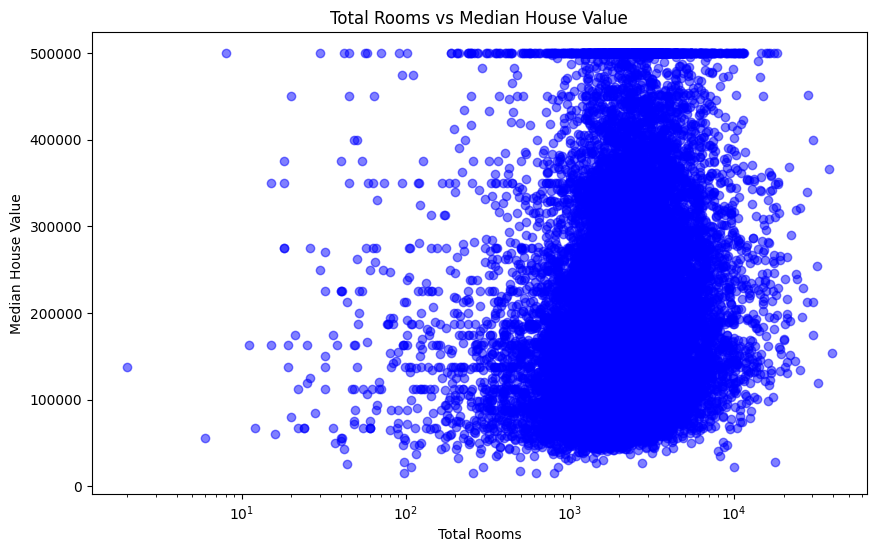

In [82]:
plt.figure(figsize=(10,6))               
plt.scatter(df['total_rooms'], df['median_house_value'], alpha=0.5, color='blue')
plt.xscale('log') # I used log scale as total_rooms has great variability
plt.xlabel('Total Rooms')                        
plt.ylabel('Median House Value')                
plt.title('Total Rooms vs Median House Value')   
plt.show()                                      

In [83]:
s_stat, s_p = stats.spearmanr(df['total_rooms'], df['median_house_value'])
print(f"Spearman's statistic: {s_stat:.4f}\nP-value: {s_p:.4f}")

Spearman's statistic: 0.2051
P-value: 0.0000


As p-value(0.000) is way below 0.05 we can reject null hypothesis(H0)

Spearman stat(0.2051) tells that there's a weak positive correlation between the number of the rooms and and the house prices(perfect positive correlation is 1)

<pre>

</pre>

### Case C

H0 - Being a $500k capped property is independent of geographic location.

H1 - Certain locations have a disproportionately higher frequency of $500k capped properties.

Test - Chi-Square. This allows us to treat the $500k cap not as a problem" but as a categorical feature to see if geography dictates luxury status.

In [84]:
capped = df['median_house_value'] > 500000
contingency_table = pd.crosstab(df['ocean_proximity'], capped)
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi2 statistic: {chi2:.4f}\nP-value: {p:.4f}\nDegrees of freedom: {dof}")

Chi2 statistic: 429.7361
P-value: 0.0000
Degrees of freedom: 4


In [85]:
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.1450


As p-value(0.000) is less than 0.05 we will reject the null hypothesis(H0).

Cramer's V shws there's a weak relationship  between capped and location, the location has imoact on house reaching 500k but it;s weak

<pre>






</pre>

### First Parameter - Mean

In [86]:
values = df.median_house_value
n = len(values)
mean = np.mean(values)
std_dev = np.std(values, ddof=1)
se = std_dev / np.sqrt(n)

In [87]:
ci_mean = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
print(f"Mean: {mean:.2f}")
print(f"95% CI for Median House Value: [{ci_mean[0]:.2f} : {ci_mean[1]:.2f}]")

Mean: 206864.41
95% CI for Median House Value: [205281.53 : 208447.29]


In [88]:
if mean > ci_mean[0] and mean < ci_mean[1]:
    print("The mean is within the confidence interval.")
else:
    print("The mean is NOT within the confidence interval.")

The mean is within the confidence interval.


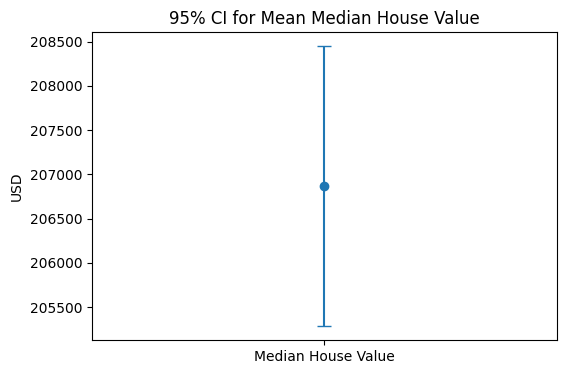

In [89]:
plt.figure(figsize=(6,4))
plt.errorbar(x=0, y=mean, yerr=[[mean-ci[0]], [ci[1]-mean]], fmt='o', capsize=5)
plt.xticks([0], ['Median House Value'])
plt.ylabel('USD')
plt.title('95% CI for Mean Median House Value')
plt.show()

Interpetation - we are 95% confident true pop. mean lies within confidence interval.

If hypothesized mean is outsed the CI we reject H0 in t-test

<pre>

</pre>

### Second Parameter - Propotion

In [90]:
capped = df['median_house_value'] > 500000
p_hat = capped.mean()
n = len(capped)
se_prop = np.sqrt(p_hat * (1 - p_hat) / n)

In [91]:
ci_prop = stats.norm.interval(0.95, loc=p_hat, scale=se_prop)
print(f"Proportion of houses > 500k: {p_hat:.4f}")
print(f"95% CI for Proportion of houses > 500k: [{ci_prop[0]:.4f} : {ci_prop[1]:.4f}]")

Proportion of houses > 500k: 0.0469
95% CI for Proportion of houses > 500k: [0.0440 : 0.0498]


In [92]:
if p_hat > ci_prop[0] and p_hat < ci_prop[1]:
    print("The proportion is within the confidence interval.")
else:
    print("The proportion is NOT within the confidence interval.")

The proportion is within the confidence interval.


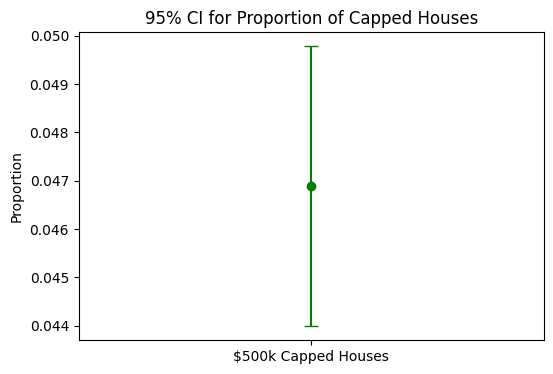

In [93]:
plt.figure(figsize=(6,4))
plt.errorbar(x=0, y=p_hat, yerr=[[p_hat - ci_prop[0]], [ci_prop[1] - p_hat]], fmt='o', capsize=5, color='green')
plt.xticks([0], ['$500k Capped Houses'])
plt.ylabel('Proportion')
plt.title('95% CI for Proportion of Capped Houses')
plt.show()

Interpretation - we are 95% sure that the true proportion of capped houses is within the ci.

If hypothesized propotion is outside CI we reject H0 complementing chi2 test

<pre>





</pre>

Case B - Post Hoc Power

In [94]:
s_stat, s_p = stats.spearmanr(df['total_rooms'], df['median_house_value'])


effect_size = s_stat
alpha = 0.05
desired_power = 0.80
n = len(df)          # sample size
d = 2 * s_stat / np.sqrt(1 - s_stat**2)



In [97]:
power_analysis = TTestPower()

required_n = power_analysis.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=desired_power,
    alternative="two-sided"
)

min_n = power_analysis.solve_power(effect_size=d, power=desired_power, alpha=alpha, alternative='two-sided')
print(f"Minimum sample size needed for 80% power: {min_n:.0f}")

Minimum sample size needed for 80% power: 47


There's only needed 47 samples for detecting the same observed effect (spearman stat = 0.2051) with 80%

Sample size is great, with help of spearman test i found that theres a weak correlation between total rooms and house prices which is robust. Small correlations can be detected reliably.

r = 0.2051 meaning while theres a relationship, it's still weak. it's enough to reject H0

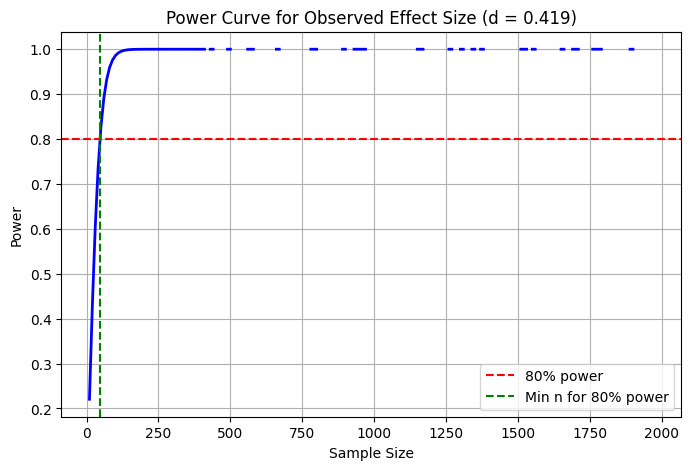

In [102]:
d = 2 * s_stat / np.sqrt(1 - s_stat**2)
alpha = 0.05
power_analysis = TTestPower()

sample_sizes = np.arange(10, 2000, 10)

powers = [power_analysis.solve_power(
    effect_size=d, 
    nobs=n, 
    alpha=alpha, 
    alternative='two-sided') 
    for n in sample_sizes]

plt.figure(figsize=(8,5))
plt.plot(sample_sizes, powers, color='blue', lw=2)
plt.axhline(y=0.8, color='red', linestyle='--', label='80% power')
plt.axvline(x=47, color='green', linestyle='--', label='Min n for 80% power')
plt.xlabel('Sample Size')
plt.ylabel('Power')
plt.title('Power Curve for Observed Effect Size (d = 0.419)')
plt.legend()
plt.grid(True)
plt.show()

<pre>




</pre>

<h2>Summary<h2>
<h5>The analysis focused on the key factors influencing house prices in the region, number of the rooms and prevalence of high value porperties(>500k). The key point is to find which characteristics strongly affect house values and what are their confidence.<h5>

<h4>Results I found<h4>
<h5>Location<h5>
Houses located near the ocean are more expensive than further inland. Proximity to the ocean has a strong impact on pricing, even more than other variables. 
<h5>Number of Rooms<h5>
There's a positive relationship between the number of the rooms and the house prices as well, but it's modest, weaker than the location. Larger houses cost more but that factor alone cannot explain price differences.
<h5>High Value houses in Common areas<h5>
In specific regions houses are priced more than 500k frequently, but again this factor's effect is also small. Whilst some vicinities are prone to high priced listings its relationship is weak compared to location.

<pre>

</pre>

<h4>Confidence</h4>
The dataset is large, more than 20k rows, which gives us high confidence in reliablity. Even weak relationships are detectable and consistent. For that reason, results are more robust: patterns observed are unlikely to chance.

Limitations
- House prices don't have a perfectly uniform or predictable pattern and extreme values are capped at 500k limiting the visibility.

- Statistical methods focus on ranking and relative differences rather than precise avgs meaning my findings describe general trends rather than exact price predictions.
- I haven't describe the other factors like the age of the house, neighborhood amenities or economic trends. The reason is that i have focused more on the task.

Recommended Actions
- Focus on Ocean-Proximate Properties
    - Invest in or develop homes near the ocean as location strongly influences price and potential returns.
- Consider House Size Strategically
    - Larger homes generally cost more, but combining size with prime location maximizes value.
- Track High-Value Properties by Region
    - Pay attention to areas where houses exceed $500k, even if the effect is small, to understand market ceilings.
- Leverage Trends for Forecasting
    - Use the observed relationships, even weak ones like room count, to support pricing strategies alongside stronger factors like location.